In [1]:
import numpy as np

In [2]:
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def update(self, params, grads):
        for key in params:
            params[key] -= self.lr * grads[key]

In [3]:
class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

    # 相比于SGD，这个在更新的时候考虑了v本身，所以可以避免方向上的轻缓问题
    def update(self, params, grads):
        if self.v is None:
            self.v = {}
            for key, val in params.items():
                self.v[key] = np.zeros_like(val)

        for key in params:
            self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
            params[key] += self.v[key]

In [4]:
class Adagrad:
    def __init__(self, lr=0.01):
        self.lr = lr
        self.h = None

    def update(self, params, grads):
        if self.h is None:
            self.h = {}
            for key, val in params.items():
                self.h[key] = np.zeros_like(val)

        for key in params:
            self.h[key] += grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

In [5]:
class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

        self.step = 0
        self.m = None
        self.v = None

    def update(self, params, grads):
        # 只在第一次调用时初始化
        if self.m is None:
            self.m = {}
            self.v = {}

            for key, val in params.items():
                self.m[key] = np.zeros_like(val)
                self.v[key] = np.zeros_like(val)

        # 每次调用 update，次数加一
        self.step += 1

        for key in params:
            g = grads[key]

            # ① 梯度的历史平均
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * g

            # ② 梯度平方的历史平均
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * g**2

            # ③ 偏差校正
            m_hat = self.m[key] / (1 - self.beta1**self.step)
            v_hat = self.v[key] / (1 - self.beta2**self.step)

            # ④ 更新参数
            params[key] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

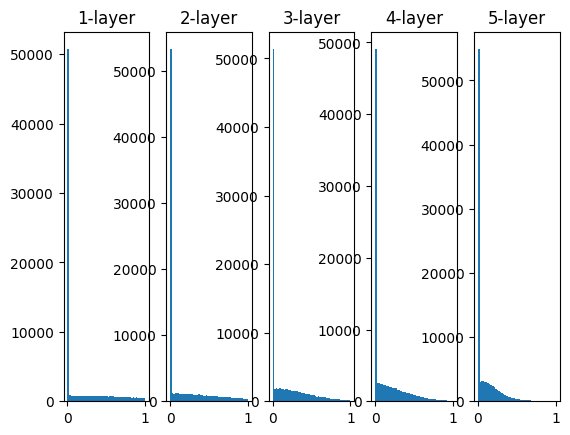

In [6]:
import matplotlib.pyplot as plt
from common.functions import *

x = np.random.randn(1000, 100)
node_num = 100  # 每个隐藏层有100个神经元
hidden_layer_size = 5  # 规定一共有5个隐藏层
activations = {}

for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i - 1]

    # w = np.random.randn(node_num, node_num) * 1
    # w = np.random.randn(node_num,node_num) * 0.01
    w = np.random.randn(node_num, node_num) / np.sqrt(node_num)

    z = np.dot(x, w)
    a = relu(z)
    activations[i] = a

for i, a in activations.items():
    plt.subplot(1, len(activations), i + 1)
    plt.title(str(i + 1) + "-layer")
    plt.hist(a.flatten(), 50, range=(0, 1))

plt.show()

In [7]:
from common.mnist import *
from common.multi_layer_net import MultiLayerNet

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

# 减少学习数据实现过拟合，只取了前三百组数据
x_train = x_train[:300]
t_train = t_train[:300]

network = MultiLayerNet(
    input_size=784, hidden_size_list=[100, 100, 100, 100, 100, 100], output_size=10
)

optimizer = SGD(lr=0.01)

max_epochs = 201
train_size = x_train.shape[0]
batch_size = 100

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)
epoch_cnt = 0

for i in range(1000000000):
    batch_mask = np.random.choice(train_size, batch_size)

    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    grads = network.gradient(x_batch, t_batch)
    optimizer.update(network.params, grads)

    if i % iter_per_epoch == 0:
        train_acc = network.accuracy(x_train, t_train)
        test_acc = network.accuracy(x_test, t_test)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)

        epoch_cnt += 1
        if epoch_cnt >= max_epochs:
            break

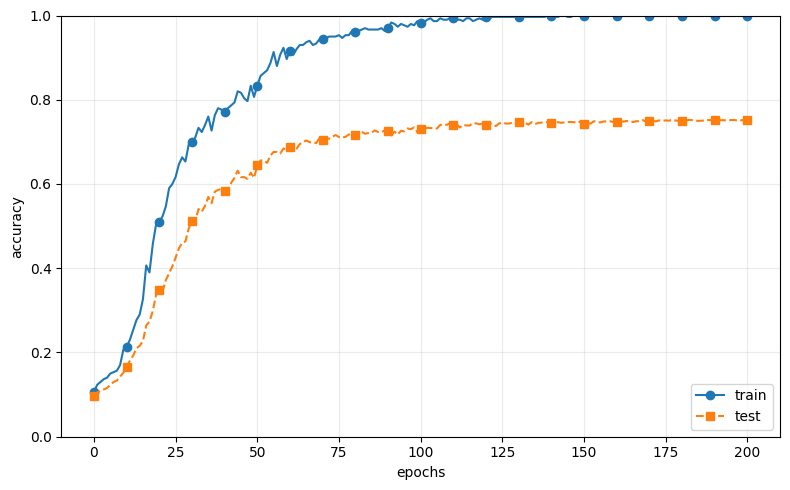

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# 每隔一个epoch记录一次准确率，按教材从0编号
epochs = np.arange(len(train_acc_list))

plt.figure(figsize=(8, 5))
plt.plot(
    epochs, train_acc_list, label="train", marker="o", markevery=10
)
plt.plot(
    epochs, test_acc_list, label="test", marker="s",
    markevery=10, linestyle="--"
)
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

评价 0: train=0.1133, test=0.1014
评价 20: train=0.4333, test=0.3026
评价 40: train=0.6933, test=0.5305
评价 60: train=0.8167, test=0.6362
评价 80: train=0.8867, test=0.6963
评价 100: train=0.8900, test=0.7135
评价 120: train=0.9000, test=0.7272
评价 140: train=0.9233, test=0.7365
评价 160: train=0.9200, test=0.7389
评价 180: train=0.9300, test=0.7429
评价 200: train=0.9200, test=0.7355


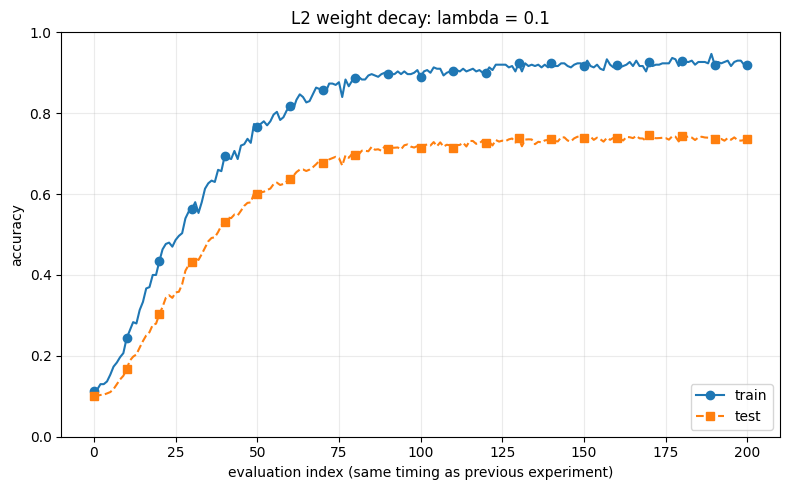

In [9]:
# 6.4.2 权值衰减（L2 正则化）
# 先运行上面的 SGD 定义和 MNIST 数据读取单元格。
# 对照教材：总损失 = 交叉熵 + (lambda / 2) * 所有权重的平方和。
# 来源：https://github.com/oreilly-japan/deep-learning-from-scratch/blob/master/common/multi_layer_net.py
import matplotlib.pyplot as plt
import numpy as np
from common.multi_layer_net import MultiLayerNet


class MultiLayerNetWithWeightDecay(MultiLayerNet):
    # 括号中的 MultiLayerNet 是父类；未改写的方法直接复用已有实现。
    def __init__(self, input_size, hidden_size_list, output_size,
                 weight_decay_lambda=0.0):
        super().__init__(input_size, hidden_size_list, output_size)
        self.weight_decay_lambda = weight_decay_lambda

    def loss(self, x, t):
        # super() 调用父类的方法，先得到原来的交叉熵损失。
        data_loss = super().loss(x, t)
        weight_decay = 0.0
        for i in range(1, self.hidden_layer_num + 2):
            W = self.params["W" + str(i)]
            weight_decay += 0.5 * self.weight_decay_lambda * np.sum(W ** 2)
        return data_loss + weight_decay

    def gradient(self, x, t):
        # 父类先完成前向和反向，求出交叉熵部分的梯度。
        # 它内部的 self.loss 会调用上面的方法；正则项的梯度在下面手动补上。
        grads = super().gradient(x, t)
        for i in range(1, self.hidden_layer_num + 2):
            key = "W" + str(i)
            # 对 (lambda / 2) * sum(W ** 2) 求导，得到 lambda * W。
            grads[key] = grads[key] + self.weight_decay_lambda * self.params[key]
        # 按教材，只惩罚 W；各个 b 的梯度不添加正则项。
        return grads


# 新建网络，从头训练；wd_ 前缀用于保留上一格无正则化实验的对象和列表。
# lambda=0.0 表示关闭权值衰减；这里先使用教材的 0.1。
wd_network = MultiLayerNetWithWeightDecay(
    input_size=784,
    hidden_size_list=[100, 100, 100, 100, 100, 100],
    output_size=10,
    weight_decay_lambda=0.1,
)
wd_optimizer = SGD(lr=0.01)
wd_train_acc_list = []
wd_test_acc_list = []

# 沿用上面已经配对截取的 300 个训练样本和 one-hot 标签。
wd_max_epochs = 201
wd_train_size = x_train.shape[0]
wd_batch_size = 100
wd_iter_per_epoch = max(wd_train_size // wd_batch_size, 1)
wd_epoch_cnt = 0

for i in range(1000000000):
    batch_mask = np.random.choice(wd_train_size, wd_batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    grads = wd_network.gradient(x_batch, t_batch)
    wd_optimizer.update(wd_network.params, grads)

    # 与前一个实验一致：i=0 时在第一次更新后就记录，横轴是评价编号。
    if i % wd_iter_per_epoch == 0:
        train_acc = wd_network.accuracy(x_train, t_train)
        test_acc = wd_network.accuracy(x_test, t_test)
        wd_train_acc_list.append(train_acc)
        wd_test_acc_list.append(test_acc)
        if wd_epoch_cnt % 20 == 0:
            print(f"评价 {wd_epoch_cnt}: train={train_acc:.4f}, test={test_acc:.4f}")
        wd_epoch_cnt += 1
        if wd_epoch_cnt >= wd_max_epochs:
            break

wd_epochs = np.arange(len(wd_train_acc_list))
plt.figure(figsize=(8, 5))
plt.plot(wd_epochs, wd_train_acc_list, label="train", marker="o", markevery=10)
plt.plot(wd_epochs, wd_test_acc_list, label="test", marker="s",
         markevery=10, linestyle="--")
plt.xlabel("evaluation index (same timing as previous experiment)")
plt.ylabel("accuracy")
plt.title("L2 weight decay: lambda = 0.1")
plt.ylim(0, 1.0)
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 与上一格的图比较训练/测试差距，不预设测试准确率一定提高。
# 两次网络随机初始化不同，这里只作现象观察。
# 不清楚时可以问我：为什么 loss 和 gradient 都要改？为什么不惩罚 b？


训练输出（随机）: [[0. 0. 0. 4.]]
本次mask: [[False False False  True]]
反向梯度: [[0. 0. 0. 1.]]
评价输出（固定）: [[0.5 1.  1.5 2. ]]
评价 0: train=0.1000, test=0.1011
评价 20: train=0.1267, test=0.1535
评价 40: train=0.2733, test=0.2563
评价 60: train=0.3033, test=0.2602
评价 80: train=0.3133, test=0.2591
评价 100: train=0.3467, test=0.2909
评价 120: train=0.3867, test=0.3105
评价 140: train=0.4600, test=0.3542
评价 160: train=0.5033, test=0.3877
评价 180: train=0.5833, test=0.4630
评价 200: train=0.6367, test=0.5010
评价 220: train=0.6833, test=0.5396
评价 240: train=0.7200, test=0.5647
评价 260: train=0.7367, test=0.5699
评价 280: train=0.7900, test=0.6072
评价 300: train=0.7967, test=0.6298


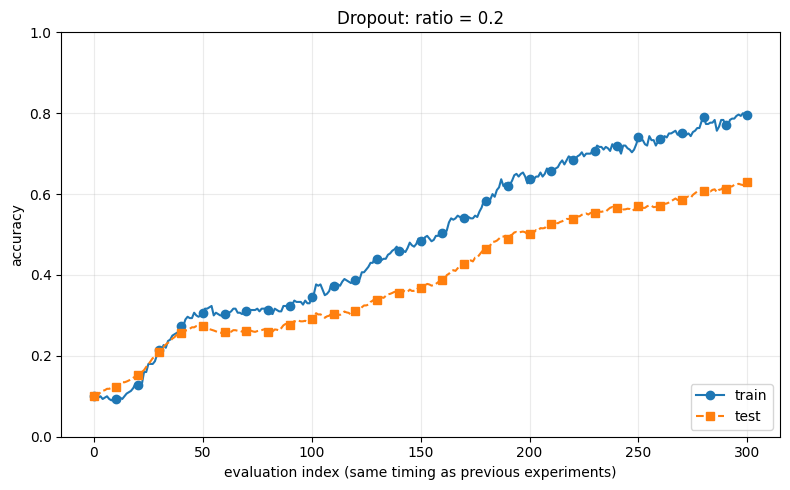

In [10]:
# 6.4.3 Dropout：训练时随机屏蔽部分输出，评价时使用全部节点。
# 先运行上面的 SGD 定义和 MNIST 数据读取单元格（one-hot 标签，训练集取前300项）。
# 对照教材写法：训练时不放大输出；评价时乘以保留比例。
# 来源：https://github.com/oreilly-japan/deep-learning-from-scratch/blob/master/common/layers.py
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np
from common.multi_layer_net import MultiLayerNet


class Dropout:
    def __init__(self, dropout_ratio=0.5):
        self.dropout_ratio = dropout_ratio  # 丢弃概率，不是保留概率
        self.mask = None

    def forward(self, x, train_flg=True):
        if train_flg:
            # *x.shape 把形状拆成参数；生成与 x 同形的 [0, 1) 随机数。
            # True 表示保留，False 表示屏蔽；每次训练前向都会重新抽取。
            self.mask = np.random.rand(*x.shape) > self.dropout_ratio
            return x * self.mask
        # 评价时不随机屏蔽；按教材乘以保留比例，匹配训练时输出的期望。
        return x * (1.0 - self.dropout_ratio)

    def backward(self, dout):
        # 复用本次前向的 mask；被屏蔽位置的梯度也为0，不能重新抽取。
        return dout * self.mask


class MultiLayerNetWithDropout(MultiLayerNet):
    def __init__(self, input_size, hidden_size_list, output_size,
                 dropout_ratio=0.2):
        super().__init__(input_size, hidden_size_list, output_size)
        # 复用已有层，在每个隐藏层的 ReLU 后插入一个独立的 Dropout。
        layers = OrderedDict()
        for name, layer in self.layers.items():
            layers[name] = layer
            if name.startswith("Relu"):
                layers["Dropout" + name[4:]] = Dropout(dropout_ratio)
        self.layers = layers

    def predict(self, x, train_flg=False):
        for layer in self.layers.values():
            if isinstance(layer, Dropout):
                x = layer.forward(x, train_flg)
            else:
                x = layer.forward(x)
        return x

    def loss(self, x, t, train_flg=True):
        # 父类 gradient 内部会调用 self.loss，所以这里默认开启训练模式。
        y = self.predict(x, train_flg=train_flg)
        return self.last_layer.forward(y, t)

    # gradient 复用父类：前向产生 mask 后，立刻倒序反向，收集 dW、db。
    # accuracy 也复用父类：它调用 predict(x)，默认 train_flg=False。
    # 因此，train准确率和test准确率都关闭随机屏蔽；区别仅是评价的数据。


# 先读懂这个小例子，再看下面的完整训练。
demo_dropout = Dropout(dropout_ratio=0.5)
demo_x = np.array([[1.0, 2.0, 3.0, 4.0]])
print("训练输出（随机）:", demo_dropout.forward(demo_x, train_flg=True))
print("本次mask:", demo_dropout.mask)
print("反向梯度:", demo_dropout.backward(np.ones_like(demo_x)))
print("评价输出（固定）:", demo_dropout.forward(demo_x, train_flg=False))


# 单独观察 Dropout：继承基础网络，不叠加上一格的 L2 权值衰减。
drop_network = MultiLayerNetWithDropout(
    input_size=784,
    hidden_size_list=[100, 100, 100, 100, 100, 100],
    output_size=10,
    dropout_ratio=0.2,
)
drop_optimizer = SGD(lr=0.01)
drop_train_acc_list = []
drop_test_acc_list = []
# 教材配套 Dropout 实验采用301次左右的epoch评价，比前两格更长。
# 这里沿用前两格的记录时机：第一次更新后就记录第0个评价点。
drop_max_epochs = 301
drop_batch_size = 100
drop_train_size = x_train.shape[0]
drop_iter_per_epoch = max(drop_train_size // drop_batch_size, 1)
drop_epoch_cnt = 0

for i in range(1000000000):
    batch_mask = np.random.choice(drop_train_size, drop_batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    grads = drop_network.gradient(x_batch, t_batch)
    drop_optimizer.update(drop_network.params, grads)

    if i % drop_iter_per_epoch == 0:
        # 即使在训练集上算准确率，也使用评价模式，不随机丢弃节点。
        train_acc = drop_network.accuracy(x_train, t_train)
        test_acc = drop_network.accuracy(x_test, t_test)
        drop_train_acc_list.append(train_acc)
        drop_test_acc_list.append(test_acc)
        if drop_epoch_cnt % 20 == 0:
            print(f"评价 {drop_epoch_cnt}: train={train_acc:.4f}, test={test_acc:.4f}")
        drop_epoch_cnt += 1
        if drop_epoch_cnt >= drop_max_epochs:
            break

drop_epochs = np.arange(len(drop_train_acc_list))
plt.figure(figsize=(8, 5))
plt.plot(drop_epochs, drop_train_acc_list, label="train", marker="o", markevery=10)
plt.plot(drop_epochs, drop_test_acc_list, label="test", marker="s",
         markevery=10, linestyle="--")
plt.xlabel("evaluation index (same timing as previous experiments)")
plt.ylabel("accuracy")
plt.title("Dropout: ratio = 0.2")
plt.ylim(0, 1.0)
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 看两条曲线的差距，也看 test 本身是否改善；不只看 train 有没有降低。
# 随机初始化不同、训练时长不同，这里是现象观察，不是严格的对照实验。
# 配套短课：../lessons/0014-dropout-mask.html
